# LIA — Análise 2: alfabetização e população idosa
**Base utilizada: Censo Demográfico 2022 (IBGE/SIDRA)**

**Grupo: AuxiLia**

**Integrantes:**
- Vinicius Kozonoe Guaglini — RM 567264
- João Victor Melo Santos — RM 566640
- Yan Lucas Gonçalves da Silva — RM 567046
- Murilo Jeronimo Ferreira Nunes — RM 560641


Para apresentar a LIA como proposta de inclusão digital, também precisamos olhar o contexto do município escolhido para o projeto: **Taiobeiras, em Minas Gerais**. O Censo ajuda a entender quantas pessoas não são alfabetizadas e como esse indicador varia entre faixas etárias.

Neste notebook vamos comparar **Taiobeiras, Minas Gerais e Brasil** nas taxas de analfabetismo da população de 15 anos ou mais. Também vamos observar os grupos etários e calcular a participação dos moradores com 60 anos ou mais, usando os dados disponíveis na tabela de população.

**Perguntas que queremos responder:**
1. Taiobeiras apresenta mais analfabetismo do que Minas Gerais e Brasil?
2. Como as taxas de analfabetismo mudam entre os grupos de idade, principalmente após os 65 anos?
3. Qual é a participação dos moradores com 60 anos ou mais em Taiobeiras e como ela se compara à participação estadual e nacional?

**Arquivos usados:** tabelas 9542 (alfabetização) e 9514 (população por idade), exportadas do SIDRA. A tabela 9514 disponível aqui contém **Taiobeiras**; para comparar a participação dos idosos, usamos também percentuais agregados de Minas Gerais e Brasil **publicados pelo IBGE**, com fonte identificada em um CSV separado. Eles não foram apresentados como se fossem uma nova exportação da tabela 9514.


In [1]:
from pathlib import Path
from IPython.display import display
import zipfile

# Os arquivos ficam ao lado dos notebooks, dentro da pasta datasets.
SUBPASTA = "censo_2022"
caminhos = [Path.cwd(), Path.cwd() / "GS_LIA_DataScience",
            Path("/content/GS_LIA_DataScience")]
RAIZ = next((p for p in caminhos if (p / "datasets/raw" / SUBPASTA).is_dir()), None)

if RAIZ is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            "Pasta de dados não encontrada. Extraia o ZIP completo e abra o notebook "
            "a partir da pasta GS_LIA_DataScience."
        )

    print("Selecione o arquivo GS_LIA_DataScience.zip (ZIP completo da entrega).")
    enviados = files.upload()
    nome_zip = next((nome for nome in enviados if nome.lower().endswith(".zip")), None)
    if nome_zip is None:
        raise FileNotFoundError("Você precisa enviar o ZIP completo, não um CSV isolado.")

    with zipfile.ZipFile(nome_zip) as pacote:
        destino = Path("/content").resolve()
        if any(not (destino / item.filename).resolve().is_relative_to(destino)
               for item in pacote.infolist()):
            raise ValueError("O ZIP contém um caminho inválido.")
        pacote.extractall(destino)

    RAIZ = Path("/content/GS_LIA_DataScience")

PASTA = RAIZ / "datasets" / "raw" / SUBPASTA
if not PASTA.is_dir():
    raise FileNotFoundError(f"Não encontrei a pasta: {PASTA}")

print("Pasta de dados:", PASTA)
import csv
import pandas as pd
import matplotlib.pyplot as plt

pasta = PASTA
saida = RAIZ / "outputs" / "censo_2022"
saida.mkdir(parents=True, exist_ok=True)

arquivos = sorted(pasta.glob("*.csv"))
print("Arquivos encontrados:")
for arquivo in arquivos:
    print("-", arquivo.name)


Pasta de dados: /mnt/data/_lia_revision/GS_LIA_DataScience/datasets/raw/censo_2022


Arquivos encontrados:
- censo_2022_alfabetizacao_por_idade.csv
- censo_2022_populacao_por_idade.csv
- ibge_2022_percentual_60_mais_publicado.csv


## 1. Abrindo as tabelas do IBGE

Antes de começar, o notebook localiza os dois CSVs que estão em `datasets/raw/censo_2022`. Eles foram baixados do SIDRA, que coloca títulos, cabeçalhos e notas junto com os números.

A função abaixo organiza esse formato para que possamos trabalhar no Pandas. No final, exibimos as primeiras linhas para conferir se os dados foram lidos corretamente. No Colab, a primeira célula de código pedirá o ZIP da entrega caso a pasta não esteja presente.


In [2]:
def ler_sidra(caminho, tabela):
    with open(caminho, encoding='utf-8-sig', newline='') as f:
        linhas = list(csv.reader(f, delimiter=';'))
    fim = next((i for i, linha in enumerate(linhas) if linha and linha[0].startswith('Fonte:')), len(linhas))
    inicio = 6  # exportação padrão do SIDRA usada neste trabalho
    dados = [linha for linha in linhas[inicio:fim] if linha and linha[0].strip()]
    if not dados:
        raise ValueError(f'Sem registros na tabela {tabela}: {caminho.name}')
    if tabela == '9514':
        cabecalho = linhas[5]
        colunas = ['territorio', 'declaracao'] + cabecalho[2:]
    else:
        # Cabeçalho da linha 4: alfabetização; linha 5: sexo
        faixa = linhas[4]
        sexo = linhas[5]
        categoria = ''
        colunas = ['territorio', 'cor_raca', 'idade']
        for i in range(3, len(sexo)):
            if i < len(faixa) and faixa[i].strip():
                categoria = faixa[i].strip()
            colunas.append(f'{categoria} | {sexo[i].strip()}')
    largura = len(colunas)
    dados = [(linha + [''] * largura)[:largura] for linha in dados]
    return pd.DataFrame(dados, columns=colunas)


def escolher_arquivo(numero):
    nomes = {
        '9514': 'censo_2022_populacao_por_idade',
        '9542': 'censo_2022_alfabetizacao_por_idade'
    }
    candidatos = [
        p for p in arquivos
        if p.stem.lower().startswith('tabela' + numero)
        or p.stem.lower().startswith(nomes[numero])
    ]
    if not candidatos:
        disponiveis = ', '.join(p.name for p in arquivos) or '(nenhum CSV)'
        raise FileNotFoundError(
            f'Não encontrei o CSV da tabela {numero} em {pasta}. '
            f'Arquivos encontrados: {disponiveis}'
        )

    # Escolhe a exportação com mais territórios e mais dados válidos.
    def pontuacao(caminho):
        try:
            df = ler_sidra(caminho, numero)
            return (df.territorio.nunique(), len(df.columns), len(df))
        except Exception:
            return (0, 0, 0)

    escolhido = max(candidatos, key=pontuacao)
    if pontuacao(escolhido) == (0, 0, 0):
        raise ValueError(f'O arquivo {escolhido.name} não parece ser um CSV SIDRA válido.')
    print(f'Tabela {numero}: {escolhido.name}')
    return escolhido

arq_pop = escolher_arquivo('9514')
arq_alf = escolher_arquivo('9542')
pop = ler_sidra(arq_pop, '9514')
alf = ler_sidra(arq_alf, '9542')
print('População:', arq_pop.name, '|', pop.shape)
print('Alfabetização:', arq_alf.name, '|', alf.shape)
display(pop.head())
display(alf.head())

Tabela 9514: censo_2022_populacao_por_idade.csv
Tabela 9542: censo_2022_alfabetizacao_por_idade.csv
População: censo_2022_populacao_por_idade.csv | (1, 12)
Alfabetização: censo_2022_alfabetizacao_por_idade.csv | (15, 12)


,territorio,declaracao,Total,60 a 64 anos,65 a 69 anos,70 a 74 anos,75 a 79 anos,80 a 84 anos,85 a 89 anos,90 a 94 anos,95 a 99 anos,100 anos ou mais
0,Taiobeiras (MG),Total,33050,1587,1247,1012,714,481,320,170,43,13


,territorio,cor_raca,idade,Total | Total,Total | Homens,Total | Mulheres,Alfabetizadas | Total,Alfabetizadas | Homens,Alfabetizadas | Mulheres,Não alfabetizadas | Total,Não alfabetizadas | Homens,Não alfabetizadas | Mulheres
0,Brasil,Total,Total,162951495,78066714,84884781,151547694,72201119,79346575,11403801,5865595,5538206
1,Brasil,Total,55 a 64 anos,21513495,10025339,11488156,19046263,8768805,10277458,2467232,1256534,1210698
2,Brasil,Total,65 anos ou mais,22169101,9619919,12549182,17679260,7687233,9992027,4489841,1932686,2557155
3,Brasil,Total,75 anos ou mais,8434333,3416517,5017816,6236913,2532102,3704811,2197420,884415,1313005
4,Brasil,Total,80 anos ou mais,4586954,1758731,2828223,3284500,1261226,2023274,1302454,497505,804949


## 2. Conferindo e preparando as tabelas

Vamos transformar as colunas de população em números. Como o CSV do SIDRA usa convenções brasileiras, a leitura precisa tratar os pontos que separam milhares e as vírgulas decimais.

Depois conferimos os territórios presentes, as linhas repetidas e os valores ausentes. Para evitar contagens duplicadas, a análise usa as linhas de total, sem somar categorias de cor/raça ou declarações que já fazem parte desses totais.


In [3]:
def numero(coluna):
    texto = coluna.astype(str).str.replace('.', '', regex=False)
    texto = texto.str.replace(',', '.', regex=False).str.strip()
    return pd.to_numeric(texto.replace({'-': None, '...': None, 'X': None, '': None}), errors='coerce')

for coluna in pop.columns[2:]:
    pop[coluna] = numero(pop[coluna])
for coluna in alf.columns[3:]:
    alf[coluna] = numero(alf[coluna])

print('Territórios na tabela 9514:', pop.territorio.unique().tolist())
print('Territórios na tabela 9542:', alf.territorio.unique().tolist())
print('Duplicadas 9514:', pop.duplicated().sum(), '| Ausentes:', pop.isna().sum().sum())
print('Duplicadas 9542:', alf.duplicated().sum(), '| Ausentes:', alf.isna().sum().sum())
print('Tipos da tabela 9542:')
print(alf.dtypes)

# Consideramos apenas os totais de sexo, cor/raça e declaração da idade.
alf = alf[alf.cor_raca.eq('Total')].copy()
pop = pop[pop.declaracao.eq('Total')].copy()

Territórios na tabela 9514: ['Taiobeiras (MG)']
Territórios na tabela 9542: ['Brasil', 'Minas Gerais', 'Taiobeiras (MG)']
Duplicadas 9514: 0 | Ausentes: 0
Duplicadas 9542: 0 | Ausentes: 0
Tipos da tabela 9542:
territorio                      object
cor_raca                        object
idade                           object
Total | Total                    int64
Total | Homens                   int64
Total | Mulheres                 int64
Alfabetizadas | Total            int64
Alfabetizadas | Homens           int64
Alfabetizadas | Mulheres         int64
Não alfabetizadas | Total        int64
Não alfabetizadas | Homens       int64
Não alfabetizadas | Mulheres     int64
dtype: object


## 3. Taxa de analfabetismo a partir dos 15 anos

Nesta parte dividimos o número de pessoas **não alfabetizadas** pela população total com 15 anos ou mais de cada território. Multiplicamos o resultado por 100 para chegar à taxa percentual.

A tabela e o gráfico mostram a diferença entre Taiobeiras, Minas Gerais e Brasil. O cálculo usa as categorias da tabela 9542, sem misturar taxa de analfabetismo do IBGE com analfabetismo funcional do INAF.


,Território,População 15+,Não alfabetizadas,Taxa (%)
0,Brasil,162951495,11403801,7.00
5,Minas Gerais,16832070,985006,5.85
10,Taiobeiras (MG),26573,3643,13.71


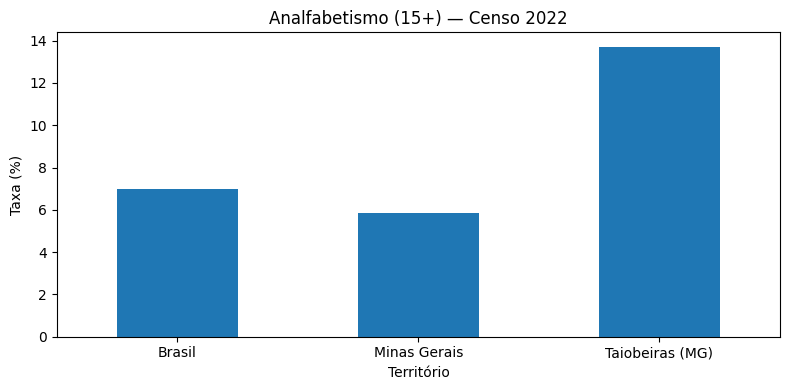

In [4]:
def coluna_alf(categoria):
    colunas = [c for c in alf.columns if c.startswith(categoria + ' |') and c.endswith('| Total')]
    if not colunas:
        raise ValueError(f'Faltou selecionar {categoria} e Sexo = Total na tabela 9542.')
    return colunas[0]

col_total = coluna_alf('Total')
col_nao = coluna_alf('Não alfabetizadas')

resumo = alf[alf.idade.eq('Total')][['territorio', col_total, col_nao]].copy()
resumo.columns = ['Território', 'População 15+', 'Não alfabetizadas']
resumo['Taxa (%)'] = (resumo['Não alfabetizadas'] / resumo['População 15+'] * 100).round(2)
resumo = resumo.drop_duplicates('Território')
display(resumo)
resumo.to_csv(saida / 'analfabetismo_15_mais.csv', index=False, encoding='utf-8-sig')

ax = resumo.plot.bar(x='Território', y='Taxa (%)', legend=False, figsize=(8, 4), rot=0)
ax.set_title('Analfabetismo (15+) — Censo 2022')
ax.set_ylabel('Taxa (%)')
plt.tight_layout()
plt.savefig(saida / 'analfabetismo_15_mais.png', dpi=150)
plt.show()

## 4. Analfabetismo por faixa etária

Depois da comparação geral, vamos verificar como a taxa muda conforme a idade. Para cada faixa, calculamos a proporção de pessoas não alfabetizadas dentro daquele mesmo grupo.

Alguns recortes do arquivo se sobrepõem, como “65 anos ou mais”, “75 anos ou mais” e “80 anos ou mais”. Não podemos somar esses grupos, pois a mesma pessoa apareceria mais de uma vez. Aqui cada taxa é calculada separadamente.


,Território,Idade,Total,Não alfabetizadas,Taxa (%)
1,Brasil,55 a 64 anos,21513495,2467232,11.47
2,Brasil,65 anos ou mais,22169101,4489841,20.25
3,Brasil,75 anos ou mais,8434333,2197420,26.05
4,Brasil,80 anos ou mais,4586954,1302454,28.39
6,Minas Gerais,55 a 64 anos,2379906,208167,8.75
7,Minas Gerais,65 anos ou mais,2543092,487392,19.17
8,Minas Gerais,75 anos ou mais,988329,256523,25.96
9,Minas Gerais,80 anos ou mais,546963,156832,28.67
11,Taiobeiras (MG),55 a 64 anos,3279,782,23.85
12,Taiobeiras (MG),65 anos ou mais,4000,1919,47.98


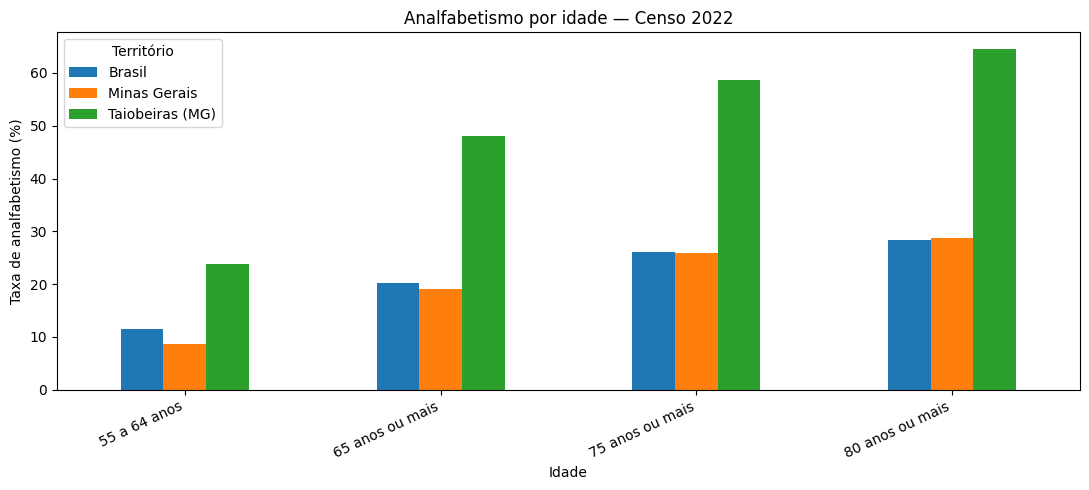

In [5]:
idades = alf[~alf.idade.eq('Total')][['territorio', 'idade', col_total, col_nao]].copy()
idades.columns = ['Território', 'Idade', 'Total', 'Não alfabetizadas']
idades['Taxa (%)'] = (idades['Não alfabetizadas'] / idades['Total'] * 100).round(2)
idades = idades.dropna(subset=['Taxa (%)'])
display(idades)
idades.to_csv(saida / 'analfabetismo_por_idade.csv', index=False, encoding='utf-8-sig')

if not idades.empty:
    graf = idades.pivot_table(index='Idade', columns='Território', values='Taxa (%)', aggfunc='first')
    graf.plot(kind='bar', figsize=(11, 5))
    plt.ylabel('Taxa de analfabetismo (%)')
    plt.title('Analfabetismo por idade — Censo 2022')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.savefig(saida / 'analfabetismo_por_idade.png', dpi=150)
    plt.show()

## 5. Quantas pessoas idosas vivem em Taiobeiras?

Somamos, na tabela 9514 de Taiobeiras, as faixas de 60 a 64 anos até 100 anos ou mais. Como são intervalos que não se sobrepõem, podemos calcular o total de pessoas idosas sem contagem duplicada.

Para que o gráfico não fique restrito a uma barra, comparamos a participação de Taiobeiras com os percentuais de **Minas Gerais (17,8%)** e **Brasil (15,8%)** publicados pelo IBGE para o Censo 2022. Os valores estaduais e nacionais estão em `ibge_2022_percentual_60_mais_publicado.csv`, com a fonte indicada. **São percentuais oficiais publicados, não uma exportação completa da tabela 9514.**


,Território,População total,População 60+,Idosos (%)
0,Taiobeiras (MG),33050,5587,16.9


,Território,Idosos (%),Fonte
0,Brasil,15.8,"IBGE (2023), Censo 2022 — Pessoas de 60 anos o..."
1,Minas Gerais,17.8,"IBGE (2023), Censo 2022 — Pessoas de 60 anos o..."
2,Taiobeiras (MG),16.9,"SIDRA/IBGE, tabela 9514 (cálculo a partir do C..."


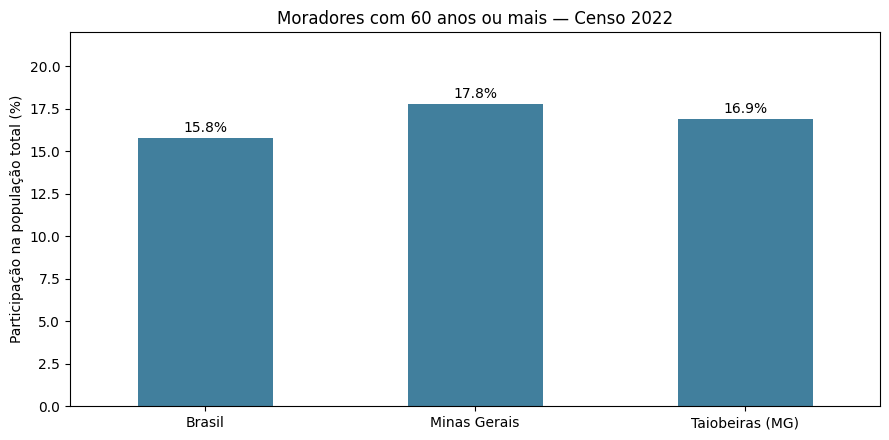

Nota: MG e Brasil são percentuais agregados publicados pelo IBGE;
o total absoluto de Taiobeiras foi calculado com a tabela 9514 anexada.


In [6]:
faixas_60 = ['60 a 64 anos', '65 a 69 anos', '70 a 74 anos', '75 a 79 anos',
             '80 a 84 anos', '85 a 89 anos', '90 a 94 anos', '95 a 99 anos', '100 anos ou mais']
faltantes = [c for c in faixas_60 if c not in pop.columns]
if faltantes:
    raise ValueError(f'Faltam as seguintes faixas na tabela 9514: {faltantes}')

idosos = pop[['territorio', 'Total'] + faixas_60].copy()
idosos['População 60+'] = idosos[faixas_60].sum(axis=1, min_count=len(faixas_60))
idosos['Idosos (%)'] = idosos['População 60+'] / idosos['Total'] * 100
idosos = idosos[['territorio', 'Total', 'População 60+', 'Idosos (%)']]
idosos.columns = ['Território', 'População total', 'População 60+', 'Idosos (%)']
idosos['Idosos (%)'] = idosos['Idosos (%)'].round(2)
display(idosos)
idosos.to_csv(saida / 'populacao_idosa.csv', index=False, encoding='utf-8-sig')

# Percentuais oficiais publicados para MG e Brasil, em um arquivo separado.
referencias = pd.read_csv(pasta / 'ibge_2022_percentual_60_mais_publicado.csv')
comparacao = pd.concat([
    referencias[['Território', 'Idosos (%)', 'Fonte']],
    idosos.assign(Fonte='SIDRA/IBGE, tabela 9514 (cálculo a partir do CSV do município)')
         [['Território', 'Idosos (%)', 'Fonte']]
], ignore_index=True)
ordem_territorios = ['Brasil', 'Minas Gerais', 'Taiobeiras (MG)']
comparacao['Território'] = pd.Categorical(comparacao['Território'],
                                          categories=ordem_territorios, ordered=True)
comparacao = comparacao.sort_values('Território')
display(comparacao)
comparacao.to_csv(saida / 'participacao_60_mais_comparacao.csv',
                  index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(9, 4.5))
comparacao.plot.bar(x='Território', y='Idosos (%)', ax=ax,
                    color='#417f9d', legend=False, rot=0)
ax.set(title='Moradores com 60 anos ou mais — Censo 2022',
       xlabel='', ylabel='Participação na população total (%)')
ax.set_ylim(0, 22)
for barra, valor in zip(ax.patches, comparacao['Idosos (%)']):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 0.35,
            f'{valor:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(saida / 'populacao_idosa.png', dpi=160)
plt.show()
print('Nota: MG e Brasil são percentuais agregados publicados pelo IBGE;')
print('o total absoluto de Taiobeiras foi calculado com a tabela 9514 anexada.')


## 6. Principais resultados e relação com a AuxiLia

Em Taiobeiras, **13,7% das pessoas com 15 anos ou mais não são alfabetizadas**, enquanto o percentual é de **5,9% em Minas Gerais** e **7,0% no Brasil**. Entre as pessoas de **65 anos ou mais**, a taxa de Taiobeiras chega a **48,0%**, contra aproximadamente **19,2% em Minas** e **20,3% no Brasil**. O município tem **5.587 moradores com 60 anos ou mais (16,9% da população)**, o que torna esse público relevante para uma possível ação de inclusão digital com apoio do **CRAS Centro**, previsto na proposta da equipe.

A participação de idosos em Taiobeiras (**16,9%**) não é maior que a de Minas (**17,8%**), mas a taxa de analfabetismo nessa faixa é consideravelmente superior. Isso reforça a importância de avaliar soluções acessíveis que evitem depender de textos longos, sem presumir que toda pessoa não alfabetizada tenha dificuldade com tecnologia.

**Limite desta análise:** o Censo mede alfabetização, e não competência digital nem uso do Gov.br. A comparação adicional de população 60+ utiliza **percentuais publicados pelo IBGE**, pois o CSV da tabela 9514 disponível para o trabalho contém somente Taiobeiras. Os resultados não medem diretamente o desempenho dos usuários da AuxiLia.

**Fontes:** IBGE/SIDRA, tabelas [9514](https://sidra.ibge.gov.br/tabela/9514) e [9542](https://sidra.ibge.gov.br/tabela/9542); IBGE, publicação *Pessoas de 60 anos ou mais de idade*, com percentuais de MG e Brasil.
